In [2]:
import sys
from pathlib import Path

# notebooks/ → корень проекта
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.db import DATA_RAW   # это уже готовый Path до data/raw

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")

df = pd.read_parquet(DATA_RAW / "cars.parquet")
print("shape:", df.shape)
print("python:", sys.executable)

shape: (30152, 63)
python: D:\anaconda_projects\car_price_ml\.venv\Scripts\python.exe


In [3]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent      # если ноутбук в notebooks/
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")

df = pd.read_parquet(PROJECT_ROOT / "data" / "raw" / "cars.parquet")
print(df.shape)

(30152, 63)


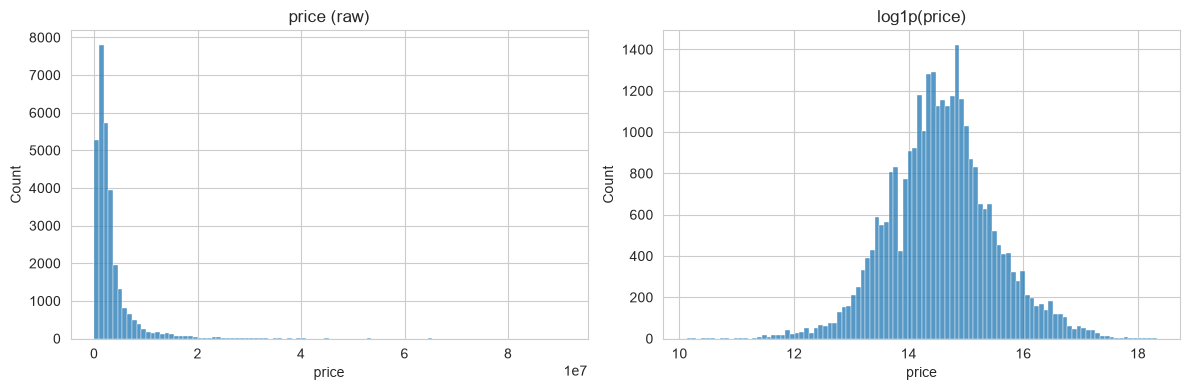

count    3.015200e+04
mean     3.302934e+06
std      4.261144e+06
min      2.500000e+04
1%       2.200000e+05
5%       5.100000e+05
25%      1.200000e+06
50%      2.100000e+06
75%      3.600000e+06
95%      1.025000e+07
99%      2.187450e+07
max      9.082300e+07
Name: price, dtype: float64

Асимметрия:
skew raw   : 5.312695309008487
skew log   : 0.07010550767672764


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=100, ax=ax[0]); ax[0].set_title("price (raw)")
sns.histplot(np.log1p(df["price"]), bins=100, ax=ax[1]); ax[1].set_title("log1p(price)")
plt.tight_layout(); plt.show()

print(df["price"].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]))
print("\nАсимметрия:")
print("skew raw   :", df["price"].skew())
print("skew log   :", np.log1p(df["price"]).skew())

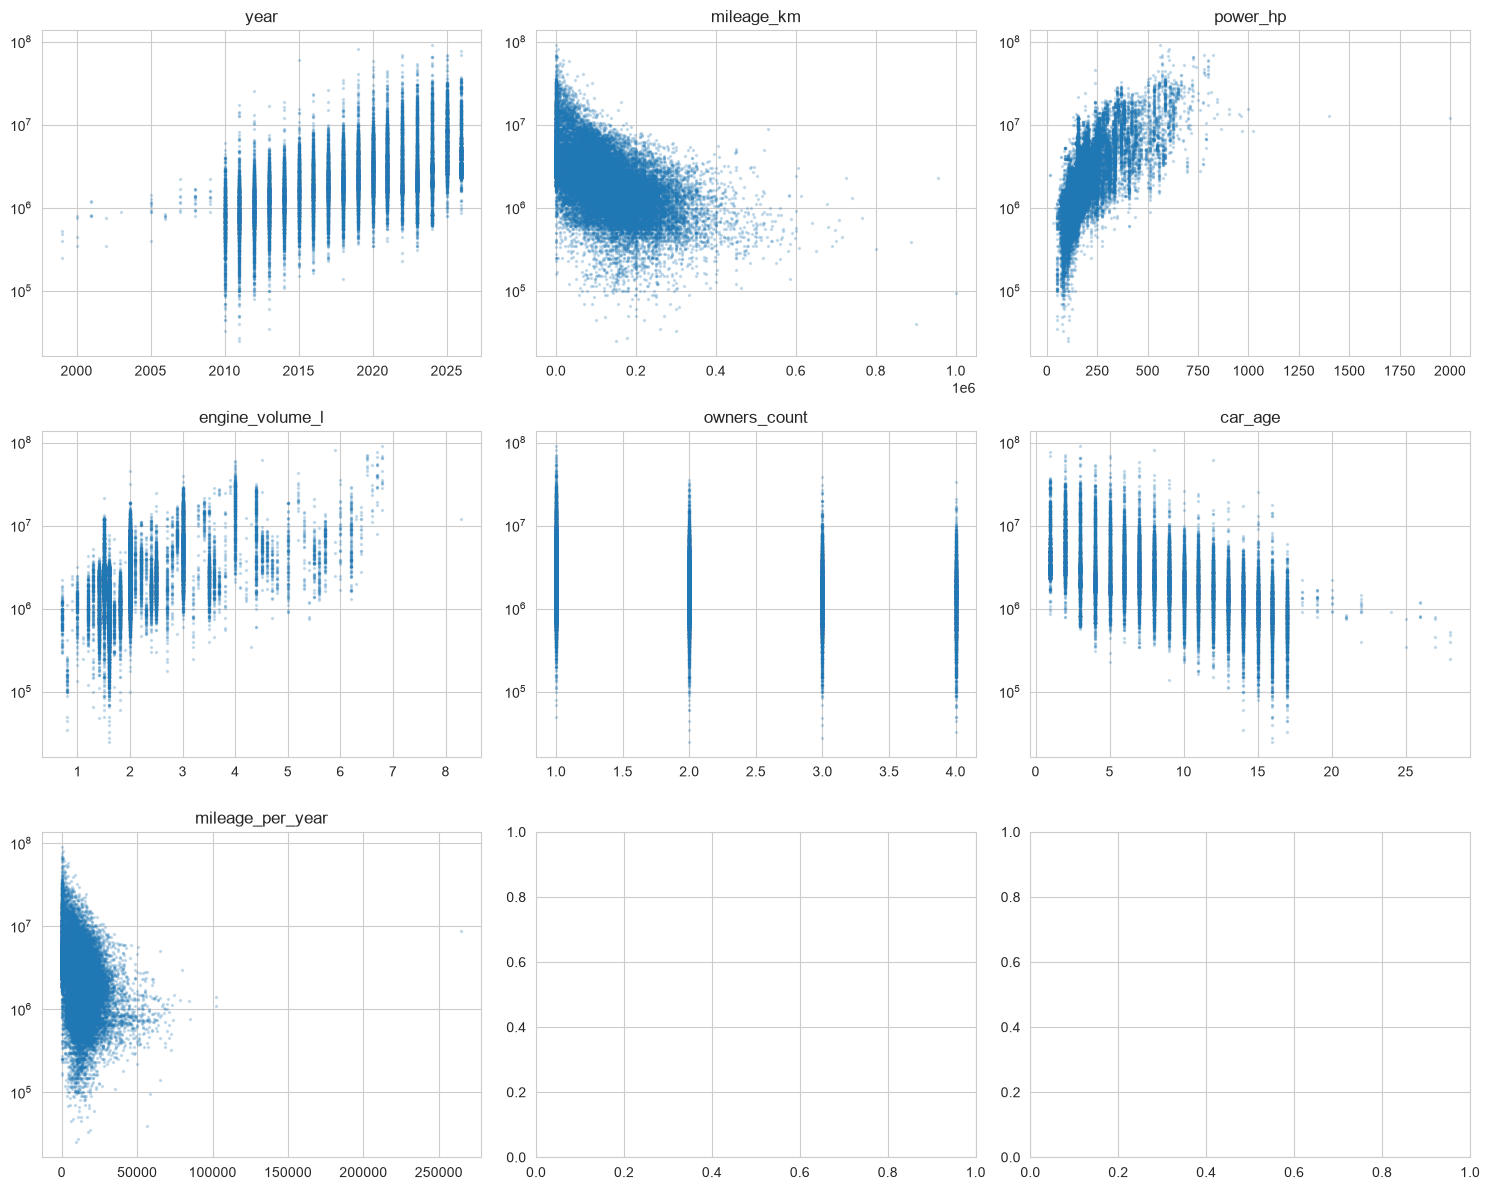

log_price           1.000000
power_hp            0.693846
year                0.613970
engine_volume_l     0.498101
owners_count       -0.294163
mileage_per_year   -0.355307
mileage_km         -0.546783
car_age            -0.613970
Name: log_price, dtype: float64


In [8]:
num_cols = ["year", "mileage_km", "power_hp", "engine_volume_l",
            "owners_count", "car_age", "mileage_per_year"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, c in zip(axes.flat, num_cols):
    sub = df[[c, "price"]].dropna()
    ax.scatter(sub[c], sub["price"], s=2, alpha=0.2)
    ax.set_yscale("log")
    ax.set_title(c)
plt.tight_layout(); plt.show()

# корреляции с log-ценой
df["log_price"] = np.log1p(df["price"])
print(df[num_cols + ["log_price"]].corr()["log_price"].sort_values(ascending=False))

In [9]:
for c in ["brand", "model", "generation", "fuel", "transmission",
          "drive", "color", "seller_type", "wheel"]:
    if c not in df.columns: continue
    g = (df.groupby(c, dropna=False)
           .agg(n=("price","size"), median=("price","median"))
           .sort_values("n", ascending=False))
    print(f"\n=== {c} ===")
    print(g.head(15))


=== brand ===
                  n     median
brand                         
BMW            2543  4080000.0
Mercedes-Benz  2410  4114500.0
Kia            1892  1545000.0
Toyota         1775  2500000.0
Hyundai        1425  1519000.0
Volkswagen     1411  1550000.0
Лада           1247   630000.0
Nissan         1119  1290000.0
Audi           1115  2795000.0
Skoda           967  1300000.0
Ford            830  1000000.0
Haval           740  2424500.0
Changan         736  2849900.0
Geely           724  2700000.0
Land Rover      564  4213502.5

=== model ===
            n     median
model                   
Octavia   430  1227500.0
Solaris   419   879000.0
E-Class   419  3050000.0
X5        417  6827000.0
5-Series  398  3350000.0
Camry     392  2300000.0
Rio       355   857000.0
Focus     343   735000.0
Tiguan    318  2129900.0
Гранта    298   587000.0
Polo      289   850000.0
X3        287  4500000.0
X6        275  5500000.0
3-Series  273  2212478.0
S-Class   271  6000000.0

=== generation ==

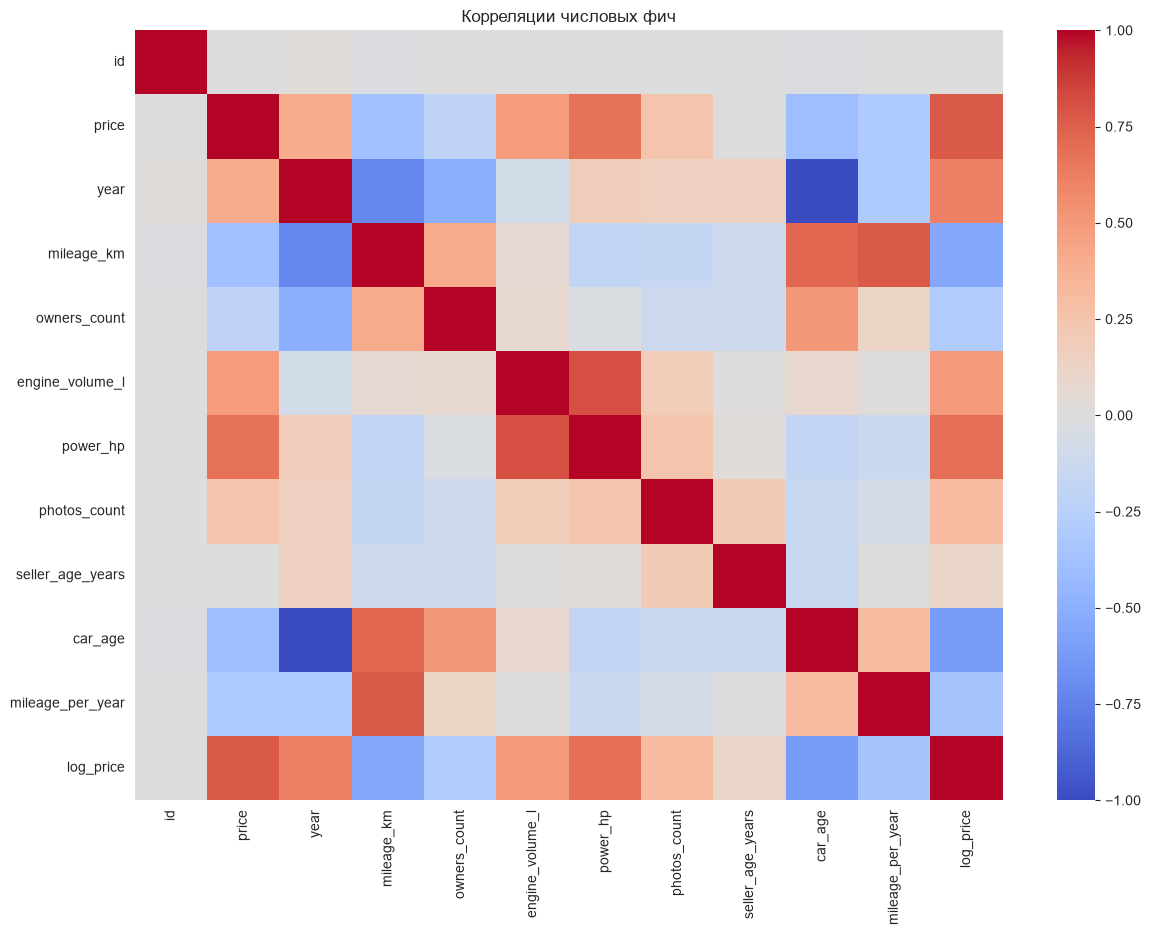

price               1.000000
log_price           0.772263
power_hp            0.678478
engine_volume_l     0.489464
year                0.406229
photos_count        0.254249
seller_age_years    0.007311
id                  0.007275
owners_count       -0.204295
mileage_per_year   -0.304599
mileage_km         -0.387343
car_age            -0.406229
Name: price, dtype: float64


In [10]:
num_for_corr = df.select_dtypes(include=["int64","float64"]).columns
corr = df[num_for_corr].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, fmt=".2f")
plt.title("Корреляции числовых фич")
plt.show()

# что сильно коррелирует с price
print(corr["price"].sort_values(ascending=False).head(20))

In [11]:
bool_cols = df.select_dtypes(include="bool").columns

rows = []
for c in bool_cols:
    m = df.loc[df[c], "price"].median()
    n = df.loc[~df[c], "price"].median()
    cnt = df[c].sum()
    rows.append({"feature": c, "n_true": cnt, "median_true": m,
                 "median_false": n, "lift": m/n if n else np.nan})

imp = pd.DataFrame(rows).sort_values("lift", ascending=False)
print(imp.to_string(index=False))

                 feature  n_true  median_true  median_false     lift
  opt_has_air_suspension    1026    8073500.0     2029000.0 3.979054
         opt_has_massage    1158    6344500.0     2000000.0 3.172250
   opt_has_premium_audio    1202    6260000.0     2026775.0 3.088651
       opt_has_autopilot     203    6200000.0     2099999.0 2.952382
    opt_has_memory_seats     652    4645000.0     2060000.0 2.254854
        opt_has_panorama    4611    3640000.0     1850000.0 1.967568
         opt_has_sunroof    6064    3490000.0     1800000.0 1.938889
       opt_has_third_row     976    3700000.0     2064000.0 1.792636
      opt_has_navigation    2605    3349000.0     2000000.0 1.674500
  opt_has_electric_doors     618    3444000.0     2076000.0 1.658960
      opt_has_led_lights    6475    2999000.0     1840000.0 1.629891
          opt_has_camera    8807    2839900.0     1800000.0 1.577722
   opt_has_apple_carplay    3263    3059900.0     1954500.0 1.565567
       cond_fresh_import    1863  

In [12]:
nulls = df.isna().sum().sort_values(ascending=False)
print(nulls[nulls > 0])

seller_is_new         8308
seller_age_years      8308
owners_count          6914
generation            1379
color                  532
seller_description     471
city                   459
engine_volume_l        393
wheel                  341
mileage_per_year       303
mileage_km             303
fuel                   276
transmission           246
power_hp               240
drive                  233
seller_type            188
photos_count           161
model                  161
brand                  161
dtype: int64


In [13]:
# очень дешёвые машины
print("Дешёвые (<300k):", (df["price"] < 300_000).sum())
print(df.loc[df["price"] < 300_000, ["brand","model","year","mileage_km","price"]].head(20))

# очень дорогие
print("\nДорогие (>20M):", (df["price"] > 20_000_000).sum())
print(df.loc[df["price"] > 20_000_000, ["brand","model","year","price"]].head(20))

# пробег 0 или абсурдный
print("\nmileage_km = 0:", (df["mileage_km"] == 0).sum())
print("mileage_km > 1M:", (df["mileage_km"] > 1_000_000).sum())

Дешёвые (<300k): 498
           brand        model  year  mileage_km   price
114         Лада       Гранта  2017    141000.0  270000
223          УАЗ      Патриот  2012    116133.0  229000
249         Лада       Гранта  2014    150000.0  250000
942         Лада       Гранта  2013    200000.0  255555
967          BMW     5-Series  2013    239000.0  280000
1472       Lifan          X60  2014    200000.0  285000
1826        Лада  2114 Самара  2012    146656.0  130000
1911        Лада  2114 Самара  2012    150000.0  220000
1990        Лада         2107  2010     57000.0   90000
2074        Лада         2107  2010    100000.0  220000
2107        Лада  2114 Самара  2010    333333.0   90000
2234        Лада       Гранта  2012    277000.0  150000
2355      Daewoo        Matiz  2012     94300.0  260000
2404        Лада  2114 Самара  2012    237000.0  150000
2442     Renault        Logan  2012    193000.0  260000
2462       Skoda        Rapid  2014    179590.0  229000
2473  Great Wall     Hover 

In [3]:
# в ноутбуке, после pd.read_parquet
print(df.groupby(df["seller_is_new"])["price"].agg(["count","median","mean"]))

               count     median          mean
seller_is_new                                
False          18467  2050000.0  3.482102e+06
True           11685  2210000.0  3.019777e+06


shape: (30152, 63)
features: 61 (num=9, bool=41, cat=11)
0:	learn: 0.6765101	test: 0.6652978	best: 0.6652978 (0)	total: 198ms	remaining: 9m 54s
200:	learn: 0.1491834	test: 0.1541654	best: 0.1541654 (200)	total: 8.78s	remaining: 2m 2s
400:	learn: 0.1299764	test: 0.1391317	best: 0.1391317 (400)	total: 17.8s	remaining: 1m 55s
600:	learn: 0.1196910	test: 0.1328074	best: 0.1328074 (600)	total: 26.2s	remaining: 1m 44s
800:	learn: 0.1125360	test: 0.1295119	best: 0.1295119 (800)	total: 35s	remaining: 1m 35s
1000:	learn: 0.1066557	test: 0.1273412	best: 0.1273412 (1000)	total: 44s	remaining: 1m 27s
1200:	learn: 0.1018318	test: 0.1257754	best: 0.1257660 (1198)	total: 52.5s	remaining: 1m 18s
1400:	learn: 0.0976078	test: 0.1245963	best: 0.1245963 (1400)	total: 1m 1s	remaining: 1m 9s
1600:	learn: 0.0936836	test: 0.1236820	best: 0.1236763 (1598)	total: 1m 9s	remaining: 1m
1800:	learn: 0.0905586	test: 0.1231058	best: 0.1231058 (1800)	total: 1m 18s	remaining: 52s
2000:	learn: 0.0875218	test: 0.1224598	

train: 22281  test: 7871
train year range: 1999–2022
test  year range: 2023–2026
0:	learn: 0.6244302	test: 0.8964529	best: 0.8964529 (0)	total: 39ms	remaining: 1m 57s
500:	learn: 0.1325461	test: 0.1949718	best: 0.1949718 (500)	total: 20.2s	remaining: 1m 40s
1000:	learn: 0.1168433	test: 0.1853971	best: 0.1853191 (996)	total: 40.9s	remaining: 1m 21s
1500:	learn: 0.1057487	test: 0.1837960	best: 0.1834831 (1467)	total: 1m 3s	remaining: 1m 3s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.1834831295
bestIteration = 1467

Shrink model to first 1468 iterations.

─── Time split ───
MAE (log)  : 0.1835
R²  (log)  : 0.9037
MAE (руб)  : 1,081,346
MAPE       : 17.19%


Худшие бренды по MAE:
              n           mae      med_mape
brand                                      
Opel          4  2.184012e+06  1.124887e+06
Honda        16  2.063730e+06  4.119926e+05
AITO         17  1.521827e+06  2.840240e+05
Soueast       1  1.134003e+06  1.134003e+06
Renault       4  1.107940e+06  1.197806e+05
Hozon         1  9.802037e+05  9.802037e+05
Mazda        54  9.273155e+05  1.859729e+05
Nordcross    25  8.952018e+05  1.378802e+05
Jeep         22  7.670238e+05  1.261566e+05
Deepal       21  5.977975e+05  4.457792e+05
Land Rover   96  5.939112e+05  1.872871e+05
TENET       180  5.861468e+05  1.689583e+05
MINI         14  5.819831e+05  3.922299e+05
Denza         6  5.545192e+05  4.887448e+05
Geely       552  5.513146e+05  1.427634e+05
Maextro       1  5.347050e+05  5.347050e+05
Toyota      221  5.135896e+05  1.587936e+05
Forthing      3  5.022539e+05  2.341193e+05
Ferrari       7  5.000940e+05  1.495025e+05
Jetta        81  4.924328e+05  1.781718e+05

Худшие пр

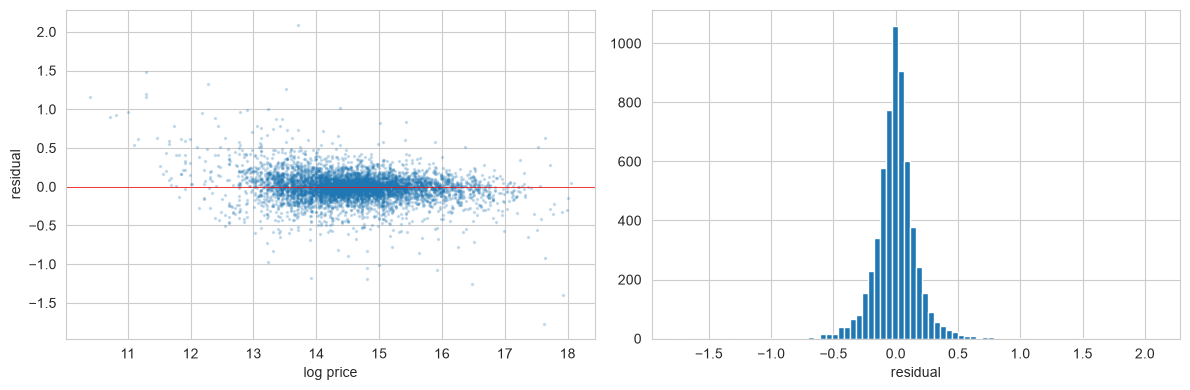

year>=2023 всего: 7871
price>10M среди свежих: 1134
              brand              model  year  mileage_km     price
440             BMW                 X6  2026         7.0  15600000
459   Mercedes-Benz            V-Class  2026        37.0  14750000
553   Mercedes-Benz          GLE-Class  2026        15.0  17480000
595   Mercedes-Benz          GLE-Class  2026         7.0  10614400
694          Toyota       Land Cruiser  2023     33816.0  11450000
716            Tank                700  2026         7.0  11499000
976   Mercedes-Benz          GLS-Class  2025      1900.0  15300000
1050          Dodge         Challenger  2023      5700.0  14500000
1122  Mercedes-Benz            G-Class  2026        20.0  33000000
1245            BMW                 X5  2024         7.0  13600000
1284  Mercedes-Benz          GLE-Class  2026         7.0  11856000
1481        Unknown            Unknown  2026         NaN  11590000
1630            BMW                 X6  2026         7.0  16690000
1704      